## Dlaczego CNN i po co tyle architektur?

Obraz to nie tylko długa lista liczb: sąsiednie piksele tworzą lokalne struktury, a ten sam wzór może pojawić się w różnych miejscach. **Sieci konwolucyjne (CNN)** wykorzystują te własności przez lokalne filtry i współdzielenie wag. Dzięki temu nie muszą uczyć się osobnego detektora krawędzi dla każdego położenia.

| Temat | Pytanie | Co zyskujemy? |
|---|---|---|
| Konwolucja i pooling | Jak rozpoznawać lokalne wzory i ograniczyć wymiar? | Podstawowe operacje CNN |
| TinyCNN, CIFAR-10 | Jak zamienić warstwy w uczący się klasyfikator? | Pierwszy punkt odniesienia |
| 1×1, dilation, GAP | Jak kontrolować koszt i zasięg widzenia modelu? | Projektowanie skuteczniejszych bloków |
| ResNet | Dlaczego pogłębianie sieci może utrudniać uczenie? | Połączenia rezydualne |
| MobileNet i EfficientNet | Jak uzyskać dobrą jakość przy ograniczonych zasobach? | Modele oszczędne obliczeniowo |
| Regularyzacja i augmentacja | Jak przeciwdziałać overfittingowi? | Lepsza generalizacja |

**Historia:** LeNet-5 (1998) -> AlexNet (2012) -> VGG (2014) -> ResNet (2015) -> MobileNet (2017) -> EfficientNet (2019).

# Convolutional Neural Network (CNN)

### Kształt tensorów

Większość błędów na początku pracy z CNN wynika z pomylenia osi `(B,C,H,W)`, a nie ze skomplikowanej matematyki. Umiejętność śledzenia rozmiarów będzie niezbędna przy łączeniu warstw i budowaniu połączeń rezydualnych.

## 0. Przygotowanie środowiska i plików

Zainstaluj znane środowisk `ml_requirements.txt`. Plik `resources/cifar_sample.npy` jest syntetycznym obrazem ćwiczeniowym RGB w formacie `(C, H, W)`; nie jest przykładem z oryginalnego CIFAR-10.

In [ ]:
from pathlib import Path

from itertools import product
import random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torchvision

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| urządzenie:", DEVICE)
DATA_PATH = next(
    (
        p
        for p in [
            Path("resources/cifar_sample.npy"),
            Path("cifar_sample.npy"),
            Path("cifar_sample(1).npy"),
        ]
        if p.exists()
    ),
    None,
)
assert (
    DATA_PATH is not None
), "Umieść syntetyczny obraz jako resources/cifar_sample.npy albo cifar_sample.npy obok notebooka."
np_image = np.load(DATA_PATH)
assert np_image.shape == (3, 32, 32)
plt.imshow(np_image.transpose(1, 2, 0))
plt.title("Obraz syntetyczny 32×32")
plt.axis("off")

### Rozgrzewka: przeczytaj kształty
**Przykład:** `torch.rand(8, 3, 32, 32)` to 8 obrazów, każdy z 3 kanałami i wymiarami 32×32.

**Ćwiczenie:** Utwórz tensor dla 12 obrazów RGB 64×64. Następnie podaj kształt jednego obrazu i liczby pikseli.

In [ ]:
batch = ...
shape_jednego = ...
liczba_pikseli = ...
if batch is None:
    raise NotImplementedError("Uzupełnij zadanie")
assert batch.shape == (12, 3, 64, 64)
assert shape_jednego == (3, 64, 64)
assert liczba_pikseli == 4096
print("Ok")

### Kontekst historyczny: od rozpoznawania cyfr do współczesnych CNN

W latach 90. model **LeNet-5** pokazał, jak wykorzystywać lokalne pola recepcyjne i współdzielone filtry przy rozpoznawaniu znaków. W pracy LeCuna architekturę zestawiono z problemem odczytywania dokumentów. CNN nie były wtedy „uniwersalnym rozwiązaniem na wszystko”: ich popularność rosła wraz z dostępnością danych i mocy obliczeniowej.

**Dlaczego uczymy się konwolucji?** ResNet, MobileNet i EfficientNet różnią się blokami, ale wszystkie korzystają z przetwarzania funkcji featurów. Kluczow są mechanizmy `kernel`, `stride` i `padding`.

**Źródło:** [LeCun et al. (1998) — LeNet i rozpoznawanie dokumentów](http://yann.lecun.com/exdb/publis/pdf/lecun-98.pdf).

**Pytanie:** co zmieniłoby się w liczbie parametrów, gdybyśmy zamiast jednego filtra współdzielonego przez cały obraz uczyli oddzielny filtr w każdym położeniu?

**Odpowiedź:**

## 1. Konwolucja jako filtr przesuwany po całym obrazie

**Intuicja:** małe okno przesuwa się po tablicy wartości (obrazie); elementy okna mnożymy przez wagi filtra, sumujemy i dodajemy bias. Kolejne filtry uczą się innych wzorców (np. krawędzi). W PyTorch `Conv2d` liczy technicznie *korelację krzyżową* (bez odwracania jądra), ale zwyczajowo mówi się „konwolucja”. (por. [Conv2d](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Conv2d.html))

**Pojęcia:** 

`kernel` - rozmiar okna; 

`stride` - przeskok okna; 

`padding` - dopisanie obramowania; 

`out_channels` - liczba filtrów/wyjściowych map cech; 

Filtr ma **wszystkie** kanały wejścia: `(C_in, k, k)`.

Dla podstawowego kwadratowego jądra zachodzi wzór:

$$H_{out}=\left\lfloor\frac{H+2P-k}{S}\right\rfloor+1,\qquad W_{out}=\left\lfloor\frac{W+2P-k}{S}\right\rfloor+1$$

Liczba wyjściowych kanałów = liczba filtrów `K`; 

liczba parametrów z biasem = $K \cdot (C_{in} \cdot k^2 + 1)$.

**Przykład:** `(3,32,32)` + 16 filtrów 3×3, `padding=1`, `stride=1` -> `(16,32,32)`, parametrów $16·(3 \cdot 9+1)=448$.

### Implementacja konwolucji od podstaw

Konwolucja dla pojedynczego obrazu o rozmiarze `C×H×W`. 

Wskazówka: górny lewy narożnik okna to `(i*stride, j*stride)`.

In [7]:
def convolution(image, filters, bias, stride=1, padding=0):
    C, H, W = image.shape
    K, Cf, kh, kw = filters.shape
    assert C == Cf and kh == kw and stride >= 1 and padding >= 0
    ho = (H + 2 * padding - kh) // stride + 1
    wo = (W + 2 * padding - kw) // stride + 1
    padded = F.pad(image, (padding, padding, padding, padding))
    result = image.new_zeros((K, ho, wo))
    for k in range(K):
        for i in range(ho):
            for j in range(wo):
                region = padded[
                    :, i * stride : i * stride + kh, j * stride : j * stride + kw
                ]
                result[k, i, j] = (region * filters[k]).sum() + bias[k]
    return result

In [9]:
img = torch.randn(3, 9, 9)
for k, stride, padding in product([1, 3, 5], [1, 2], [0, 1, 2]):
    weight = torch.randn(2, 3, k, k)
    bias = torch.randn(2)
    mine = convolution(img, weight, bias, stride, padding)
    reference = F.conv2d(
        img.unsqueeze(0), weight, bias, stride=stride, padding=padding
    ).squeeze(0)
    torch.testing.assert_close(mine, reference, atol=1e-5, rtol=1e-5)
print("Działa")

Działa


### Dlaczego pooling pojawił się w klasycznych CNN?

Wczesne CNN, w tym LeNet-5, korzystały z operacji zmniejszających rozdzielczość map cech; w LeNet stosowano *subsampling* oparty na uśrednianiu, a nie dokładnie taki max pooling jak poniżej. Późniejsze architektury, np. AlexNet, szeroko wykorzystywały max pooling.

**Po co go poznajemy?** Pooling zmniejsza koszt następnych warstw i ogranicza wrażliwość na niewielkie przesunięcia aktywacji, lecz może też usuwać informację o dokładnym położeniu. We współczesnych architekturach czasem zastępuje się go konwolucją ze `stride > 1`.

**Źródła:** Krizhevsky, Sutskever, Hinton (2012), [*ImageNet Classification with Deep Convolutional Neural Networks*](https://doi.org/10.1145/3065386).

**Pytanie:** w których zadaniach utrata informacji o dokładnej pozycji może być szczególnie kosztowna? 

**Odpowiedź:** 

## 2. Pooling
Max-Pooling 2×2, `stride=2` bierze maksimum z każdego okna, a Average-Pooling średnią, przez co z reguły dzieli wysokość i szerokość przez 2. **Nie ma wag do nauczenia** i działa niezależnie dla każdego kanału.

**Uwaga na padding:** `max_pool2d` oraz `AvgPool2d` traktują obszar poza wejściem jak $−\infty$, a nie `0`. Inaczej dla danych ujemnych wynik byłby błędny. W PyTorch ograniczenie: `padding <= kernel_size//2`.

**Mini-rachunek:** z macierzy `[[1,5],[3,2]]` max pooling 2×2 daje `5`, average pooling daje `2.75`.

**Policz:** policz wynik max poolingu 2×2, stride 2 na macierzy poniżej; wynik powinien mieć 2×2.

In [ ]:
macierz = torch.tensor(
    [
        [1.0, 5.0, 2.0, 0.0],
        [3.0, 2.0, 9.0, 4.0],
        [7.0, 1.0, 2.0, 8.0],
        [0.0, 6.0, 5.0, 3.0],
    ]
)
wynik_reczny = ...
assert torch.equal(wynik_reczny, torch.tensor([[5.0, 9.0], [7.0, 8.0]]))

### Własny własny max pooling
Użyj `F.pad(image, (...), value=float('-inf'))`, a następnie trzech pętli po kanale i współrzędnych wyjścia.

In [10]:
def max_pooling(image, kernel_size=2, stride=2, padding=0):
    C, H, W = image.shape
    assert 0 <= padding <= kernel_size // 2
    ho = (H + 2 * padding - kernel_size) // stride + 1
    wo = (W + 2 * padding - kernel_size) // stride + 1
    padded = F.pad(image, (padding, padding, padding, padding), value=float("-inf"))
    result = image.new_empty((C, ho, wo))
    for c in range(C):
        for i in range(ho):
            for j in range(wo):
                result[c, i, j] = padded[
                    c,
                    i * stride : i * stride + kernel_size,
                    j * stride : j * stride + kernel_size,
                ].max()
    return result

In [11]:
for kernel, stride, pad in product([2, 3, 4], [1, 2, 3], [0, 1]):
    if pad > kernel // 2:
        continue
    im = torch.randn(3, 10, 10) - 3
    expected = F.max_pool2d(
        im.unsqueeze(0), kernel_size=kernel, stride=stride, padding=pad
    ).squeeze(0)
    actual = max_pooling(im, kernel, stride, pad)
    torch.testing.assert_close(actual, expected)
print("Działa!")

Działa!


### Od LeNet do AlexNet: po co budujemy TinyCNN?

Przełom **AlexNet** (2012) unaocznił znaczenie większych sieci konwolucyjnych trenowanych na dużych zbiorach i z wykorzystaniem GPU. Późniejszy **VGG** (2014) pokazał wartość powtarzania prostych filtrów 3×3 w głębszych sieciach. Nasz `TinyCNN` nie odtwarza tych architektur: jest **małym modelem bazowym**, w którym można samodzielnie prześledzić przepływ danych.

**Źródła:** [Krizhevsky et al., 2012 (AlexNet)](https://doi.org/10.1145/3065386); Simonyan, Zisserman (2014), [*Very Deep Convolutional Networks for Large-Scale Image Recognition*](https://arxiv.org/abs/1409.1556).

## 3. Maye CNN
`Conv2d` ekstrahuje cechy, `ReLU` wprowadza nieliniowość, pooling zmniejsza rozdzielczość, `Flatten` przygotowuje cechy, a `Linear` zwraca **logity** — nieznormalizowane wyniki klas. `CrossEntropyLoss` oczekuje na wejściu logitów i indeksów klas;

**Przykład kształtów:** `B×3×32×32 -> Conv(3→16) -> B×16×32×32 -> MaxPool(2) -> B×16×16×16 -> Conv(16→32) -> B×32×16×16 -> GAP -> B×32×1×1 -> Flatten -> B×32 -> Linear -> B×10`.

**Zadanie:** dokończ `TinyCNN` używając `nn.Sequential`. Włącz `AdaptiveAvgPool2d(1)`, żeby nie uzależniać klasyfikatora od sztywnych wymiarów.

In [ ]:
class TinyCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            ...,
        )
        self.classifier = ...

    def forward(self, x):
        return self.classifier(self.features(x))

In [ ]:
net = TinyCNN()
assert net(torch.randn(4, 3, 32, 32)).shape == (4, 10)
assert net(torch.randn(2, 3, 48, 48)).shape == (2, 10)
print("Liczba parametrów:", sum(p.numel() for p in net.parameters()))

### Batch, logity i gradienty
Wsteczna propagacja (`backward`) liczy gradienty względem parametrów; `optimizer.step()` zmienia wagi. `optimizer.zero_grad()` czyści gradienty z poprzedniej iteracji.

**Zadanie:** jeden krok treningu na syntetycznym minibatchu. `x` ma kształt `(8,3,32,32)`, `y` to indeksy od 0 do 9. Zobacz, że po `backward` co najmniej jeden gradient jest niepusty.

In [ ]:
x = torch.rand(8, 3, 32, 32)
y = torch.randint(0, 10, (8,))
model = TinyCNN().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
opt.zero_grad(set_to_none=True)
logits = model(x.to(DEVICE))
loss = criterion(logits, y.to(DEVICE))
loss.backward()
assert any(p.grad is not None for p in model.parameters())
opt.step()

### Po co diagnozować trening, a nie tylko podawać accuracy?

Nawet poprawna architektura może uczyć się źle. Porównanie metryk treningowych i walidacyjnych pomaga odróżnić niedouczenie (*underfitting*) od nadmiernego dopasowania (*overfitting*). Walidacja służy do wyboru ustawień; test powinien pozostać niezależną oceną końcową.

**Do zapamiętania:** pojedynczy wynik z jednej epoki nie jest wystarczającym dowodem przewagi modelu. Kontroluj ziarno losowe, podział danych, budżet treningu i sposób ewaluacji.

## 4. Trening i diagnoza jakości
**Epoka** = jednokrotne przejście przez zbiór treningowy; `DataLoader` grupuje dane w minibatch'e. `model.train()` włącza zachowanie treningowe m.in. dropout/BatchNorm, a `model.eval()` przełącza je na ewaluację. `torch.no_grad()` wyłącza zapisywanie gradientów. `accuracy` to udział poprawnie sklasyfikowanych przykładów.

**Ważne rozróżnienie:** zbiory `train` (uczenie), `validation` (dobór parametrów), `test` (końcowa, możliwie jednokrotna ocena). **Nie dostrajaj modelu na zbiorze testowym**.

In [13]:
def train_one_epoch(model, loader, optimizer, criterion, device=DEVICE):
    model.train()
    loss_sum = 0.0
    correct = 0
    total = 0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(inputs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        size = labels.size(0)
        loss_sum += loss.item() * size
        correct += (logits.argmax(1) == labels).sum().item()
        total += size
    return {"loss": loss_sum / total, "accuracy": correct / total}


@torch.no_grad()
def evaluate(model, loader, criterion, device=DEVICE):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        logits = model(inputs)
        size = labels.size(0)
        loss_sum += criterion(logits, labels).item() * size
        correct += (logits.argmax(1) == labels).sum().item()
        total += size
    return {"loss": loss_sum / total, "accuracy": correct / total}

**Pytanie:** Co zmieni się po usunięciu model.eval() w evaluate? 

**Odpowiedź:** 

### Skąd CIFAR-10 i dlaczego go uzywamy?

Zbiór **CIFAR-10** został opisany przez Alexa Krizhevsky'ego w 2009 r. Ma małe obrazy 32×32, więc nadaje się do dydaktycznych eksperymentów i szybszych porównań architektur. Nie jest jednak substytutem wszystkich rzeczywistych problemów wizji komputerowej.

**Źródło:** Krizhevsky (2009), [*Learning Multiple Layers of Features from Tiny Images*](https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf).

**Przed uruchomieniem:** 100 epok na CPU może być czasochłonne (około kilkanaście minut do godziny); flaga `RUN_CIFAR` i liczba `EPOCHS` są do świadomego ustawienia. Nie interpretuj jakości na podstawie niewielkiej liczby epok.

## 5. CIFAR-10
CIFAR-10: 50 000 obrazów treningowych i 10 000 testowych, RGB 32×32, 10 klas. Dane zostaną pobrane **tylko** po ustawieniu flagi. Do porównywania hiperparametrów warto wydzielić walidację ze zbioru treningowego (tu 45 000/5 000). Dane testowe zostaw na końcowy pomiar.

**Augmentacja** modyfikuje obraz treningowy, zachowując sens etykiety. Dla CIFAR-10 często sprawdza się `RandomCrop(padding=4)` i `RandomHorizontalFlip`; pionowy flip może zmieniać semantykę, więc nie jest bezpiecznym wyborem domyślnym. Zbiór walidacyjny i testowy nie dostają losowych transformacji.

**Zadanie:** Opis spodziewanego wpływu augmentacji na róznicę `train accuracy – validation accuracy`.  

Ustawienie `RUN_CIFAR=True` porówna 2 konfiguracje przy takim samym seedzie i liczbie epok. Na CPU użyj krótkiego treningu i małego podzbioru.

In [ ]:
RUN_CIFAR = False
EPOCHS = ...  # Spróbuj osiągnąć 75% accuracy
USE_AUGMENTATION = True
if RUN_CIFAR:
    from torchvision.datasets import CIFAR10
    from torchvision import transforms as T
    from torch.utils.data import DataLoader, Subset

    base = T.ToTensor()
    augmented = T.Compose(
        [T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor()]
    )
    ds_train_aug = CIFAR10(
        root="data",
        train=True,
        download=True,
        transform=augmented if USE_AUGMENTATION else base,
    )
    ds_train_plain = CIFAR10(root="data", train=True, download=False, transform=base)
    ds_test = CIFAR10(root="data", train=False, download=True, transform=base)
    indices = np.random.default_rng(SEED).permutation(len(ds_train_aug))
    tr_idx, val_idx = indices[:45000], indices[45000:]
    tr = Subset(ds_train_aug, tr_idx)
    val = Subset(ds_train_plain, val_idx)
    train_loader = DataLoader(tr, batch_size=128, shuffle=True, num_workers=0)
    val_loader = DataLoader(val, batch_size=256, num_workers=0)
    test_loader = DataLoader(ds_test, batch_size=256, num_workers=0)
    print("train/validation/test:", len(tr), len(val), len(ds_test))

train/validation/test: 45000 5000 10000


Epoka 1: train={'loss': 2.144176851272583, 'accuracy': 0.1878} | validation={'loss': 2.0883001335144042, 'accuracy': 0.2384}
Epoka 2: train={'loss': 2.011583457522922, 'accuracy': 0.24775555555555556} | validation={'loss': 1.979610710144043, 'accuracy': 0.2556}
Epoka 3: train={'loss': 1.9195137074152628, 'accuracy': 0.28844444444444445} | validation={'loss': 1.9291658149719237, 'accuracy': 0.2838}
Epoka 4: train={'loss': 1.856686219300164, 'accuracy': 0.30877777777777776} | validation={'loss': 1.8509969734191896, 'accuracy': 0.3172}
Epoka 5: train={'loss': 1.8099758752187094, 'accuracy': 0.3277555555555556} | validation={'loss': 1.8022022151947021, 'accuracy': 0.325}
Epoka 6: train={'loss': 1.7755464866638184, 'accuracy': 0.33726666666666666} | validation={'loss': 1.760547430038452, 'accuracy': 0.3458}
Epoka 7: train={'loss': 1.7499578454547458, 'accuracy': 0.3476} | validation={'loss': 1.7549926183700562, 'accuracy': 0.3532}
Epoka 8: train={'loss': 1.7299147498660616, 'accuracy': 0.35

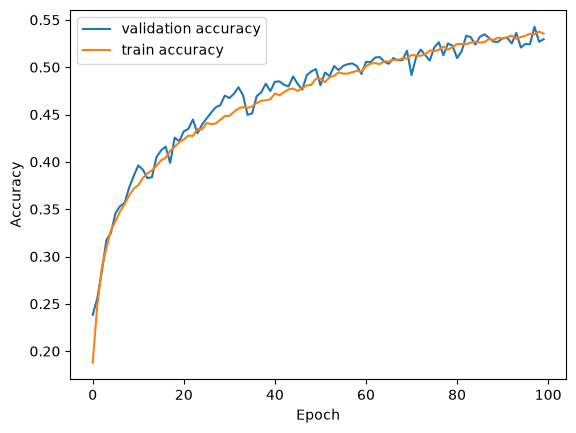

In [21]:
if RUN_CIFAR:
    model_cifar = TinyCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model_cifar.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    history = []
    for ep in range(EPOCHS):
        tr_metrics = train_one_epoch(model_cifar, train_loader, optimizer, criterion)
        val_metrics = evaluate(model_cifar, val_loader, criterion)
        history.append((tr_metrics, val_metrics))
        print(f"Epoka {ep+1}: train={tr_metrics} | validation={val_metrics}")
    plt.plot([v["accuracy"] for t, v in history], label="validation accuracy")
    plt.plot([t["accuracy"] for t, v in history], label="train accuracy")
    plt.legend()
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.show()

### Historyczna motywacja: „więcej warstw” to nie jedyna droga

Projektanci CNN szukali sposobów na ograniczenie liczby parametrów i poszerzenie pola recepcyjnego bez drastycznego wzrostu kosztu. **Network in Network** (2013/2014) spopularyzował konwolucje 1×1 i global average pooling w architekturze klasyfikacyjnej; prace nad segmentacją wykorzystywały konwolucje *atrous/dilated*, by powiększyć kontekst bez proporcjonalnej utraty rozdzielczości.

**Źródła:** Lin, Chen, Yan (2013), [*Network in Network*](https://arxiv.org/abs/1312.4400); Yu, Koltun (2015), [*Multi-Scale Context Aggregation by Dilated Convolutions*](https://arxiv.org/abs/1511.07122).

**Pytanie:** która z operacji zmienia liczbę kanałów, która zwiększa kontekst, a która redukuje wymiary przestrzenne do 1×1? 

**Odpowiedź:** 

## 6. Konwolucja 1×1, dilation, GAP i liczba parametrów
- **1×1 (pointwise):** miesza informacje pomiędzy kanałami, nie zwiększa przestrzennego pola recepcyjnego.
- **Dilation:** „dziury” między wagami filtra. Efektywny rozmiar filtra $k_{eff} = k + (k-1) \cdot (d-1)$.
- **GAP / Global Average Pooling:** uśrednia każdą mapę `(H,W)` do jednej liczby; może radykalnie odchudzić klasyfikator.

**Zadanie 6A:** uzupełnij przewidywane wymiary dla 4 przykładów, następnie sprawdź je kodem. Zwróć uwagę, że GAP nie ma trenowalnych parametrów.

In [ ]:
features = torch.randn(4, 32, 16, 16)
pointwise = nn.Conv2d(32, 64, 1)
dilated = nn.Conv2d(32, 32, 3, padding=2, dilation=2)
gap = nn.AdaptiveAvgPool2d(1)
for name, layer in [("conv 1x1", pointwise), ("dilated 3x3", dilated), ("GAP", gap)]:
    print(
        name,
        "wyjście:",
        tuple(layer(features).shape),
        "parametry:",
        sum(p.numel() for p in layer.parameters()),
    )
# TODO policz parametry w conv1x1 32 -> 64 (łącznie z biasami).

### ResNet: rozwiązanie problemu trenowania bardzo głębokich sieci

Po sukcesach AlexNet i VGG naturalnym pomysłem było zwiększanie głębokości sieci. W praktyce coraz głębszy model bez odpowiednich mechanizmów bywał trudniejszy do optymalizacji (tzw. *degradation problem* — nie jest to po prostu overfitting). **ResNet** He i współautorów (wersja preprintu 2015, publikacja CVPR 2016) zaproponował uczenie poprawki `F(x)` do sygnału wejściowego zamiast wyłącznie pełnego odwzorowania.

Połączenie `x + F(x)` to jeden z najważniejszych wzorców projektowych współczesnych sieci. Pomaga trenować głębokie modele i jest punktem odniesienia do oceny nowych bloków.

**Źródło:** He, Zhang, Ren, Sun (2016), [*Deep Residual Learning for Image Recognition*](https://arxiv.org/abs/1512.03385).

## 7. Skip connections i bloki rezydualne
Główną ideą jest `y = F(x) + shortcut(x)`. Wariant `shortcut(x)=x` to **identity shortcut**; kiedy kształty nie pasują, stosuje się projekcję 1×1 ze stride. To ułatwia przepływ informacji i gradientów, choć nie gwarantuje lepszego wyniku każdego modelu.

**Zadanie:** Zapisasz kształty po operacjach dla wejścia `(2,32,16,16)` i bloku z 64 kanałami, stride=2 w bloku rezydualnym.  

**Pytanie:** Dlaczego zwykłe `x + F(x)` zgłaszałoby błąd? 

**Odpowiedź:**

In [14]:
class BasicResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels, 3, stride=stride, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.shortcut = (
            nn.Identity()
            if in_channels == out_channels and stride == 1
            else nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        )
        self.activation = nn.ReLU()

    def forward(self, x):
        return self.activation(self.main(x) + self.shortcut(x))

### MobileNet i EfficientNet: CNN poza serwerem

Kiedy sieci osiągnęły wysoką jakość, pojawiło się pytanie: **czy można uruchamiać je na telefonach i urządzeniach o ograniczonym zużyciu energii?** **MobileNetV1** (2017) wykorzystał konwolucje *depthwise separable* do ograniczenia kosztu. **MobileNetV2** (2018) rozwinął bloki *inverted residual*; **MobileNetV3** (2019) dodatkowo uwzględniał wyszukiwanie architektur i praktyczną efektywność. **EfficientNet** (2019) pokazał, że warto wspólnie skalować głębokość, szerokość i rozdzielczość sieci (*compound scaling*).

ResNet ilustruje optymalizację głębokich sieci, zaś MobileNet i EfficientNet dają kompromis między jakością a kosztem.

**Źródła:** Howard et al. (2017), [*MobileNets*](https://arxiv.org/abs/1704.04861); Sandler et al. (2018), [*MobileNetV2*](https://arxiv.org/abs/1801.04381); Howard et al. (2019), [*Searching for MobileNetV3*](https://arxiv.org/abs/1905.02244); Tan, Le (2019), [*EfficientNet*](https://arxiv.org/abs/1905.11946).

## 8. Depthwise separable convolution, MobileNet i EfficientNet
Pełna konwolucja 3×3 ma $9*C_{in} \cdot C_{out}$ wag (bez bias). **Depthwise** stosuje osobny filtr 3×3 dla każdego kanału (`groups=C_in`): $9 \cdot C_{in}` wag. **Pointwise** miesza kanały za pomocą konwolucji 1×1: $C_in \cdot C_out$ wag. Razem zwykle znacznie mniej wag, ale rzeczywista szybkość zależy od sprzętu i implementacji.

MobileNet wykorzystuje takie operacje dla efektywności; EfficientNet stosuje m.in. bloki MBConv i złożone skalowanie głębokości/szerokości/rozdzielczości. `weights=None` oznacza **losowe parametry**.

**Zadanie:** dla $C_{in}=32$, $C_{out}=64$ policz liczbę wag dla obu metod, porównaj z kodem.

In [26]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.depthwise = nn.Conv2d(cin, cin, 3, padding=1, groups=cin, bias=False)
        self.pointwise = nn.Conv2d(cin, cout, 1, bias=False)

    def forward(self, x):
        return self.pointwise(self.depthwise(x))

**Pytanie:** Co dzieje się z liczbą parametrów, gdy podwajasz liczbę kanałów? 

**Odpowiedź:** 

### Kiedy powinniśmy porównywać modele?

Wtedy gdy posiadają taki sam zbiór danych i preprocessing, jednakowy sprzęt, rozmiar batcha, liczbę i numery seedów, jawne `weights=None` lub zdefiniowane wagi pretrenowane. Liczba parametrów, FLOPs, pamięć i opóźnienie nie są zamienne.

### Gotowe architektury
ResNet18, MobileNetV3-Small i EfficientNet-B0 to różne rodziny modeli, sprawdź liczbę ich parametrów. Samo porównanie liczby parametrów **nie** jest porównaniem jakości, dokładności ani czasu odpowiedzi.

In [ ]:
RUN_MODEL_COMPARISON = False
if RUN_MODEL_COMPARISON:
    from torchvision.models import resnet18, mobilenet_v3_small, efficientnet_b0

    for name, factory in [
        ("ResNet18", resnet18),
        ("MobileNetV3-Small", mobilenet_v3_small),
        ("EfficientNet-B0", efficientnet_b0),
    ]:
        model_compare = factory(weights=None, num_classes=10).eval()
        with torch.inference_mode():
            shape = tuple(model_compare(torch.randn(1, 3, 224, 224)).shape)
        print(
            name,
            "parametry:",
            sum(p.numel() for p in model_compare.parameters()),
            "wyjście:",
            shape,
        )
        assert shape == (1, 10)

### Dlaczego dobre wyniki treningowe nie wystarczą?

**Dropout** (Srivastava et al., 2014) i **stochastic depth** (Huang et al., 2016) ograniczają zależność modelu od wybranych aktywacji lub ścieżek obliczeń podczas treningu. **AdamW** (Loshchilov, Hutter, 2017/2019) rozdziela weight decay od aktualizacji wynikającej z gradientu w adaptacyjnych optymalizatorach.

**Po co poznajemy regularyzację?** W praktyce wybór architektury to tylko część sukcesu: model musi działać na niewidzianych obrazach, a nie jedynie dopasować dane treningowe.

**Źródła:** [Dropout](https://jmlr.org/papers/v15/srivastava14a.html); [Deep Networks with Stochastic Depth](https://arxiv.org/abs/1603.09382); [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101).

**Pytanie:** czy mniejszy błąd treningowy zawsze oznacza lepszy model?

## 9. Regularyzacja
 
**Dropout** losowo wyłącza aktywacje w treningu (a nie w ewaluacji). 

**Weight decay** wpływa na rozmiary wag; `AdamW` stosuje rozdzielone weight decay. 

**Label smoothing** zmniejsza pewność etykiet treningowych. 

**Stochastic depth / DropPath** wyłącza losowo całe gałęzie rezydualne dla niektórych przykładów (tylko w treningu).

**Zadanie:** sprawdź, że dropout zmienia tensor w `train()`, a nie zmienia go w `eval()`; zobacz loss dla róznych `label_smoothing`, np. `label_smoothing=0.1`.

In [ ]:
dropout = nn.Dropout(p=0.5)
ones = torch.ones(1000)
dropout.train()
print("odsetek zer podczas treningu:", (dropout(ones) == 0).float().mean().item())
dropout.eval()
assert torch.equal(dropout(ones), ones)
logits = torch.tensor([[2.0, 0.0, -1.0], [0.0, 1.0, 2.0]])
target = torch.tensor([0, 2])
loss_smooth = nn.CrossEntropyLoss(label_smoothing=0.1)(logits, target)
if loss_smooth is not None:
    print("Loss smooth:", loss_smooth.item())

### DropPath
W treningu tworzona jest maska o kształcie `(B,1,1,1)` pochodząca z rozkładu Bernoulliego, zachowuja próbkę z prawdopodobieństwem `1-p`. Wynik zostaje przeskalowany przez `1/(1-p)`. DropPath stosuje się do gałęzi residual.

In [16]:
class DropPath(nn.Module):
    def __init__(self, p=0.1):
        super().__init__()
        assert 0 <= p < 1
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0:
            return x
        keep = 1 - self.p
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        mask = x.new_empty(shape).bernoulli_(keep)
        return x * mask / keep

### Augmentacja: wbudowana w trening wiedza o obrazie

Już w epoce AlexNet losowe wycinki i odbicia pomagały zwiększyć różnorodność przykładów. Później pojawiły się bardziej zautomatyzowane strategie, m.in. **RandAugment** (Cubuk et al., 2020), ograniczające liczbę decyzji potrzebnych do dobrania transformacji.

Augumentacja uczy model, które przekształcenia obrazu nie powinny wpływać na zmianę jego klasy. To założenie zależy od zadania: pionowe odbicie może być sensowne dla labelu samochodu (por. Tesla Rocket), ale niekoniecznie dla znaku lub cyfry (por. 6 i 9).

**Źródła:** [AlexNet](https://doi.org/10.1145/3065386); Cubuk et al., [*RandAugment: Practical Automated Data Augmentation with a Reduced Search Space*](https://arxiv.org/abs/1909.13719).

**Pytanie:** jak mogłaby zaszkodzić zbyt agresywna augmentacja? 

**Odpowiedź:**

### MixUp i CutMix: co, jeśli zmieszamy także etykiety?

W klasycznej augmentacji przekształcamy jeden obraz. **MixUp** (Zhang et al., 2017/2018) miesza liniowo dwa obrazy i odpowiadające im etykiety. **CutMix** (Yun et al., 2019) przenosi fragment jednego obrazu do drugiego i dostosowuje udział etykiet do obszaru wymienionego fragmentu.

Te techniki pokazują, że regularyzacja może działać nie tylko na wagach i pojedynczych zdjęciach, ale też na **relacjach między przykładami**. Należy jednak sprawdzić, czy taka strategia ma sens dla danego zadania.

**Źródła:** Zhang et al., [*mixup: Beyond Empirical Risk Minimization*](https://arxiv.org/abs/1710.09412); Yun et al., [*CutMix: Regularization Strategy to Train Strong Classifiers with Localizable Features*](https://arxiv.org/abs/1905.04899).

**Pytanie:** dlaczego po MixUp etykiety nie zawsze są pojedynczymi liczbami całkowitymi? 

**Odpowiedź:**

## 10. MixUp i CutMix, czyli mieszanie całych minibatchy
**MixUp** interpoluje pary obrazów i ich etykiet, a **CutMix** przenosi prostokątny fragment z innego obrazu oraz odpowiednio miesza etykiety. Wynikowe etykiety to `soft targets` z rozmiarem `(B,num_classes)`, a nie pojedyncze indeksy. Operacje wykonujemy **na minibatchu po DataLoaderze**; nie ma gwarancji poprawy, więc testuj je oddzielnie.

**Zadanie:** Włącz demo i zweryfikuj, że w każdym wierszu soft targets suma wynosi 1.   

**Pytanie**: Dlaczego nie warto stosować MixUp do zbioru walidacyjnego? 

**Odpowiedź:**

In [ ]:
RUN_MIX_DEMO = False
if RUN_MIX_DEMO:
    from torchvision.transforms import v2

    images = torch.rand(8, 3, 32, 32)
    labels = torch.arange(8)
    for name, transform in [
        ("MixUp", v2.MixUp(num_classes=10, alpha=0.2)),
        ("CutMix", v2.CutMix(num_classes=10, alpha=1.0)),
    ]:
        mixed, soft = transform(images.clone(), labels.clone())
        assert mixed.shape == images.shape and soft.shape == (8, 10)
        assert torch.allclose(soft.sum(1), torch.ones(8))
        print(name, "etykieta pierwszej próbki:", soft[0])

## Pytania kontrolne
1. Dlaczego filtr konwolucyjny obejmuje wszystkie kanały wejściowe?

2. Czym różnią się `stride`, `padding`, `dilation`?

3. Dlaczego pooling ma zero trenowalnych parametrów?

4. Czy wolno wstawić `softmax` przed `CrossEntropyLoss`?

5. Po co połączenia rezydualne?

6. Dlaczego `model.eval()` nie jest tym samym co `torch.no_grad()`?

7. Jaka jest różnica między dropout a DropPath?

8. Czym różni się MixUp od CutMix i jaki mają format etykiet?

Odpowiedzi: 
1. 

2. 

3. 

4. 

5. 

6. 

7. 

8.

### Najwazniejsze artykuły

1. [LeCun et al. (1998) — LeNet i rozpoznawanie dokumentów](http://yann.lecun.com/exdb/publis/pdf/lecun-98.pdf).
2. [Krizhevsky et al. (2012) — AlexNet](https://proceedings.neurips.cc/paper_files/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf).
3. [He et al. (2016) — ResNet](https://arxiv.org/abs/1512.03385).
4. [Howard et al. (2017) — MobileNet](https://arxiv.org/abs/1704.04861).
5. [Tan, Le (2019) — EfficientNet](https://arxiv.org/abs/1905.11946).
